[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_rolling_moments/BA_L2_rolling_moments.ipynb)

# BA_L2_rolling_moments: Stability of Kurtosis over Time

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Skewness and excess kurtosis of Bitcoin daily log returns on rolling 365-day windows, 2018 to 18 September 2026, showing how single extreme days move the estimates.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Data and method

Daily log returns of Bitcoin in percent, from 1 January 2018 to 18 September 2026. On each window of the last 365
returns, the sample skewness and excess kurtosis,

$$\hat S_t = \frac{1}{365}\sum_{j=0}^{364} z_{t-j}^3, \qquad \hat K_t = \frac{1}{365}\sum_{j=0}^{364} z_{t-j}^4 - 3,$$

with $z$ standardised within the window (pandas uses the bias-corrected versions of both).

**How to read the chart.** If the tail index is below 4, the population kurtosis is infinite and the sample kurtosis
has no stable limit: one crash enters the window, the estimate jumps, and it falls back 365 days later when the crash
leaves the window.

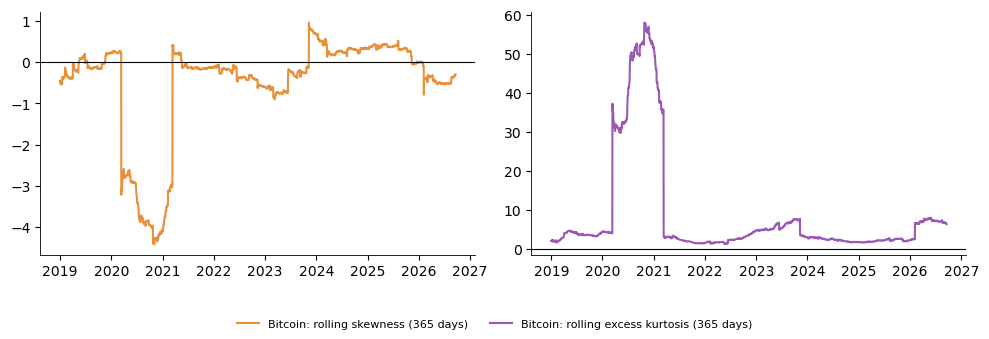

In [5]:
b = rets(prices('BTC-USD.CC'))
rs, rk = b.rolling(365).skew(), b.rolling(365).kurt()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(rs.index, rs, color=BTC, label='Bitcoin: rolling skewness (365 days)'); ax[0].axhline(0, color='black', lw=0.8)
ax[1].plot(rk.index, rk, color=ETH, label='Bitcoin: rolling excess kurtosis (365 days)'); ax[1].axhline(0, color='black', lw=0.8)
slide_legend(fig, 0.12, ncol=2)
save_fig(fig, 'ba_l2_rolling_moments')

In [6]:
print(f'Rolling excess kurtosis: minimum {rk.min():.1f}, maximum {rk.max():.1f} (window ending {rk.idxmax():%d %B %Y}), '
      f'last {rk.iloc[-1]:.1f} ({rk.index[-1]:%d %B %Y})')
print(f'Rolling skewness: minimum {rs.min():.2f}, maximum {rs.max():.2f}, last {rs.iloc[-1]:.2f}')
print(f'Worst day in the sample: {b.idxmin():%d %B %Y}, {b.min():.1f}%')

Rolling excess kurtosis: minimum 1.3, maximum 58.0 (window ending 26 October 2020), last 6.4 (18 September 2026)
Rolling skewness: minimum -4.41, maximum 0.96, last -0.29
Worst day in the sample: 12 March 2020, -46.5%
